# Практическая работа: поиск аномалий во временном ряду и оценка NAB Score

**Датасет:** `ambient_temperature_system_failure.csv` из набора [Numenta Anomaly Benchmark (NAB)](https://github.com/numenta/NAB).

## Цель работы

Используя инструменты ноутбука 04_Практика_анализ_данных_мониторинга_TS.ipynb проанализировать датасет ambient_temperature_system_failure.csv и постараться получить наибольший NAB Score для датасета.
Самостоятельно изучить алгоритм расчета NAB Score и реализовать его в ноутбуке (взамен стандартной оценки по метрикам precision/recall/F1).

## 1. Импорты и параметры эксперимента

Используются инструменты из исходной практики: `pandas`, `numpy`, `matplotlib`, `statsmodels` и `scikit-learn`.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPRegressor
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
RANDOM_STATE = 42
NAB_PROFILE = "standard"
PROBATIONARY_PERCENT = 0.15
plt.rcParams["figure.figsize"] = (13, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
np.random.seed(RANDOM_STATE)

print("Основной профиль оценки:", NAB_PROFILE)
print("Доля probationary-периода NAB:", PROBATIONARY_PERCENT)

Основной профиль оценки: standard
Доля probationary-периода NAB: 0.15


## 2. Загрузка данных и официальной разметки NAB

В `combined_windows.json` NAB для этого файла указаны два аномальных окна. Включаем обе границы каждого окна, как это делает оригинальная реализация оценщика.

In [2]:
DATA_FILENAME = "ambient_temperature_system_failure.csv"
data_candidates = [
    Path(DATA_FILENAME),
    Path.cwd() / DATA_FILENAME,
    Path("/mnt/data") / DATA_FILENAME,
]
DATA_PATH = next((p for p in data_candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        f"Не найден {DATA_FILENAME}. Поместите CSV рядом с ноутбуком и повторите запуск."
    )

df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)

# Официальная разметка NAB: labels/combined_windows.json
anomaly_windows = [
    (pd.Timestamp("2013-12-15 07:00:00"), pd.Timestamp("2013-12-30 09:00:00")),
    (pd.Timestamp("2014-03-29 15:00:00"), pd.Timestamp("2014-04-20 22:00:00")),
]

assert list(df.columns[:2]) == ["timestamp", "value"], f"Неожиданные столбцы: {df.columns.tolist()}"
assert df["timestamp"].is_monotonic_increasing, "Временные метки должны быть отсортированы"
assert not df["timestamp"].duplicated().any(), "Найдены повторяющиеся timestamp"
assert not df[["timestamp", "value"]].isna().any().any(), "В исходных данных есть пропуски"
for start, end in anomaly_windows:
    assert (df["timestamp"] == start).any(), f"Начало окна отсутствует в данных: {start}"
    assert (df["timestamp"] == end).any(), f"Конец окна отсутствует в данных: {end}"

df["label"] = 0
for start, end in anomaly_windows:
    df.loc[df["timestamp"].between(start, end, inclusive="both"), "label"] = 1

print(f"Файл: {DATA_PATH}")
print(f"Наблюдений: {len(df):,}")
print(f"Период: {df['timestamp'].min()} — {df['timestamp'].max()}")
print(f"Пропусков в исходных столбцах: {int(df[['timestamp', 'value']].isna().sum().sum())}")
print(f"Наблюдений внутри размеченных окон: {int(df['label'].sum()):,}")
for i, (start, end) in enumerate(anomaly_windows, start=1):
    count = int(df["timestamp"].between(start, end, inclusive="both").sum())
    print(f"Окно {i}: {start} — {end}; точек в файле: {count}")
df.head()

Файл: ambient_temperature_system_failure.csv
Наблюдений: 7,267
Период: 2013-07-04 00:00:00 — 2014-05-28 15:00:00
Пропусков в исходных столбцах: 0
Наблюдений внутри размеченных окон: 726
Окно 1: 2013-12-15 07:00:00 — 2013-12-30 09:00:00; точек в файле: 363
Окно 2: 2014-03-29 15:00:00 — 2014-04-20 22:00:00; точек в файле: 363


,timestamp,value,label
0,2013-07-04 00:00:00,69.880835,0
1,2013-07-04 01:00:00,71.220227,0
2,2013-07-04 02:00:00,70.877805,0
3,2013-07-04 03:00:00,68.959400,0
4,2013-07-04 04:00:00,69.283551,0


## 3. Первичный анализ данных (EDA)

Проверяем распределение температуры, частоту измерений, разрывы во временной шкале и основные статистики. Метка `label` нужна только для визуализации окон, но далее не используется как точечная метрика качества.

In [3]:
display(df["value"].describe().to_frame("temperature"))
deltas = df["timestamp"].diff().dropna()
print("Медианный интервал:", deltas.median())
print("Наиболее частые интервалы:")
display(deltas.value_counts().head(10).rename_axis("интервал").to_frame("количество"))
large_gaps = df.loc[deltas[deltas > pd.Timedelta(hours=1)].index, ["timestamp", "value"]].copy()
large_gaps["gap_from_previous"] = deltas.loc[large_gaps.index].values
print("Число пропусков ожидаемых часовых меток:", int((df["timestamp"].max() - df["timestamp"].min()) / pd.Timedelta(hours=1)) + 1 - len(df))
print("Разрывы длиннее одного часа:")
display(large_gaps)

,temperature
count,7267.000000
mean,71.242433
std,4.247509
min,57.458406
25%,68.369411
50%,71.858493
75%,74.430958
max,86.223213


Медианный интервал: 0 days 01:00:00
Наиболее частые интервалы:


,количество
интервал,
0 days 01:00:00,7256
0 days 02:00:00,1
1 days 08:00:00,1
2 days 00:00:00,1
6 days 16:00:00,1
4 days 00:00:00,1
2 days 23:00:00,1
1 days 06:00:00,1
0 days 03:00:00,1


Число пропусков ожидаемых часовых меток: 621
Разрывы длиннее одного часа:


,timestamp,value,gap_from_previous
578,2013-07-28 03:00:00,72.782389,0 days 02:00:00
580,2013-07-29 12:00:00,73.243443,1 days 08:00:00
1276,2013-08-29 11:00:00,67.619708,2 days 00:00:00
1550,2013-09-16 12:00:00,72.696440,6 days 16:00:00
1815,2013-10-01 12:00:00,75.664288,4 days 00:00:00
2064,2013-10-14 19:00:00,72.983034,2 days 23:00:00
5385,2014-03-03 09:00:00,64.737526,1 days 06:00:00
5739,2014-03-18 05:00:00,66.693992,0 days 03:00:00
5883,2014-03-24 19:00:00,71.943363,0 days 15:00:00
6114,2014-04-10 15:00:00,69.954680,7 days 06:00:00


### 3.1 Временной ряд и официальные аномальные окна

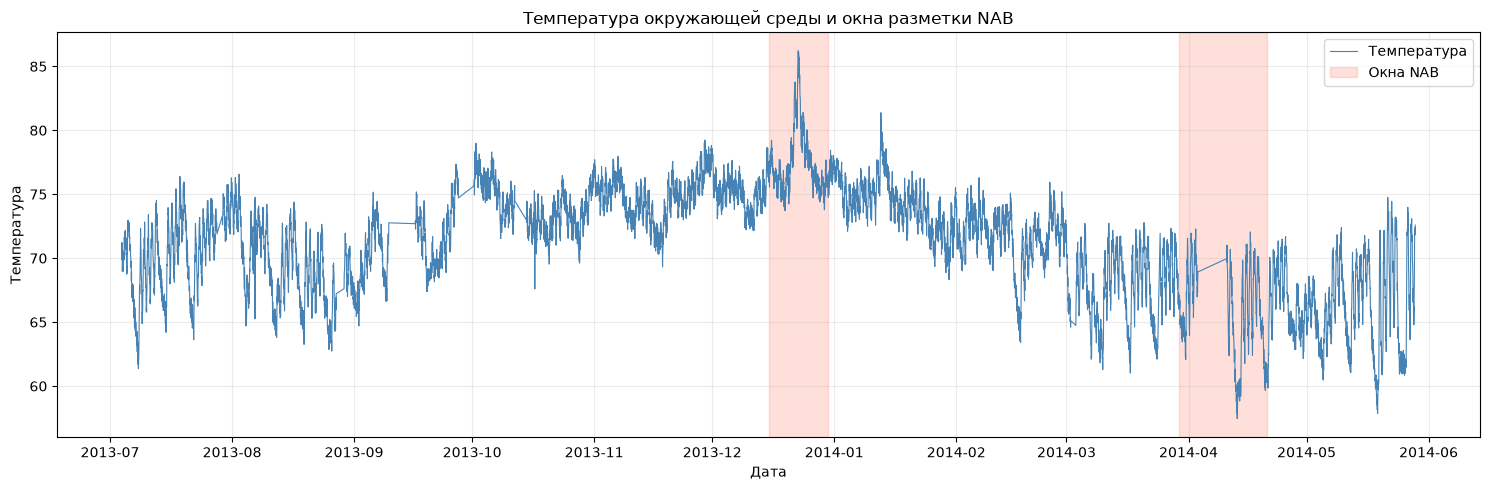

In [4]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(df["timestamp"], df["value"], lw=0.8, color="steelblue", label="Температура")
for i, (start, end) in enumerate(anomaly_windows):
    ax.axvspan(start, end, color="tomato", alpha=0.2, label="Окна NAB" if i == 0 else None)
ax.set(title="Температура окружающей среды и окна разметки NAB", xlabel="Дата", ylabel="Температура")
ax.legend()
plt.tight_layout()
plt.show()

### 3.2 Увеличенные фрагменты размеченных окон

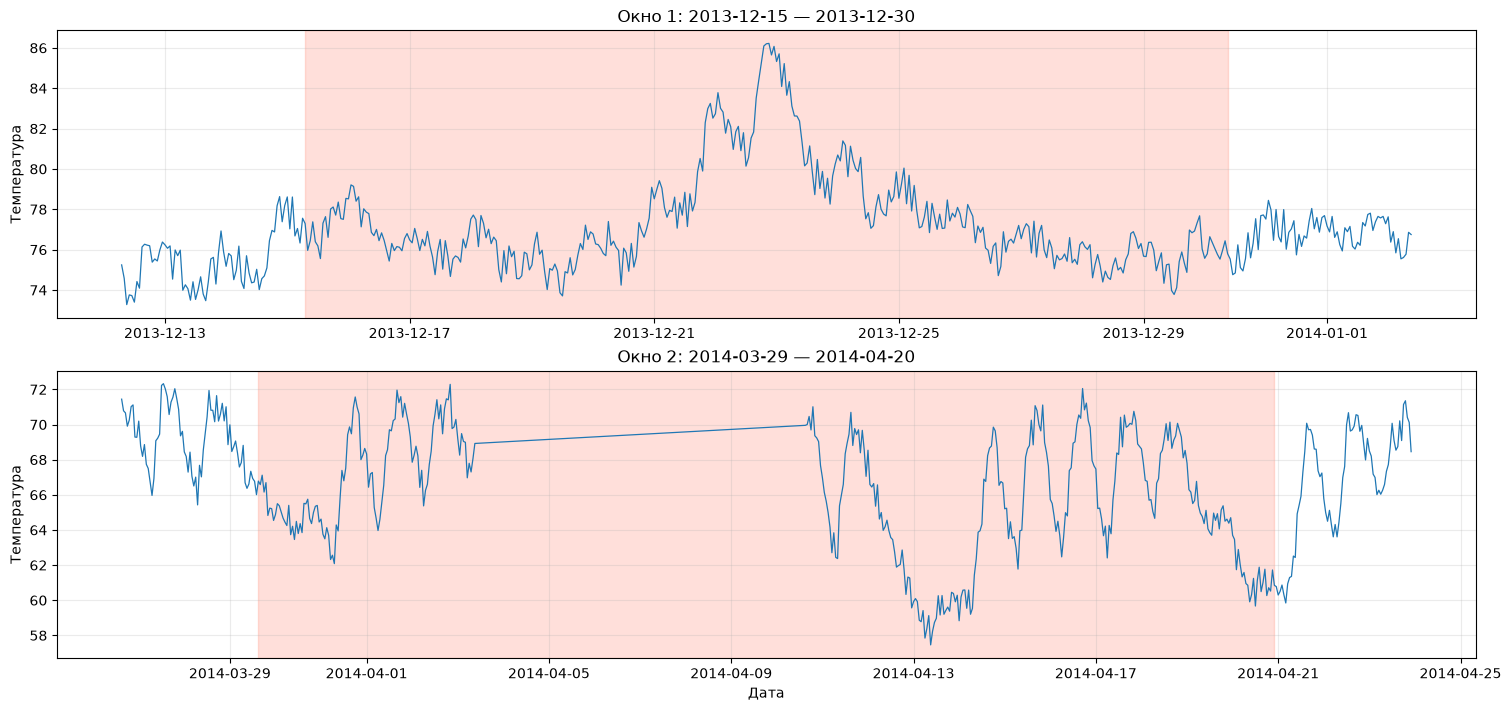

In [5]:
fig, axes = plt.subplots(len(anomaly_windows), 1, figsize=(15, 7), constrained_layout=True)
for i, (ax, (start, end)) in enumerate(zip(axes, anomaly_windows), start=1):
    part = df[df["timestamp"].between(start - pd.Timedelta(days=3), end + pd.Timedelta(days=3))]
    ax.plot(part["timestamp"], part["value"], lw=0.9)
    ax.axvspan(start, end, color="tomato", alpha=0.2)
    ax.set(title=f"Окно {i}: {start:%Y-%m-%d} — {end:%Y-%m-%d}", ylabel="Температура")
axes[-1].set_xlabel("Дата")
plt.show()

### 3.3 Интерактивная визуализация Plotly

В дополнение к статическим графикам строим интерактивный график исходного ряда: можно приближать временные интервалы и исследовать точки внутри каждого официального окна NAB. Этот раздел использует те же официальные границы, что и оценщик.


In [6]:
try:
    import plotly.graph_objects as go

    fig_interactive = go.Figure()
    fig_interactive.add_trace(go.Scatter(
        x=df["timestamp"], y=df["value"], mode="lines",
        name="Температура", line={"width": 1},
        hovertemplate="%{x|%Y-%m-%d %H:%M}<br>Температура: %{y:.2f}<extra></extra>",
    ))
    for i, (start, end) in enumerate(anomaly_windows, start=1):
        fig_interactive.add_vrect(
            x0=start, x1=end, fillcolor="red", opacity=0.12,
            line_width=0, annotation_text=f"Окно NAB {i}", annotation_position="top left",
        )
    fig_interactive.update_layout(
        title="Интерактивный температурный ряд с окнами аномалий NAB",
        xaxis_title="Время", yaxis_title="Температура",
        hovermode="x unified", template="plotly_white", height=500,
    )
    fig_interactive.show()
    print("Plotly-график построен; границы окон взяты из официальной разметки NAB.")
except ImportError:
    print("Plotly не установлен; доступны статические графики Matplotlib из предыдущих ячеек.")


Plotly-график построен; границы окон взяты из официальной разметки NAB.


## 4. Стационарность и сезонная структура

ADF и KPSS дополняют описательную статистику: у них противоположные нулевые гипотезы. Эти тесты сами по себе не обнаруживают аномалии и не участвуют в расчёте NAB Score.

In [7]:
adf_result = adfuller(df["value"].to_numpy(dtype=float), autolag="AIC")
print(f"ADF statistic: {adf_result[0]:.4f}")
print(f"ADF p-value: {adf_result[1]:.6g}")
print("ADF: " + ("отвергаем H0 о единичном корне" if adf_result[1] < 0.05 else "нет оснований отвергнуть H0 о единичном корне"))

kpss_result = kpss(df["value"].to_numpy(dtype=float), regression="c", nlags="auto")
print(f"KPSS statistic: {kpss_result[0]:.4f}")
print(f"KPSS p-value: {kpss_result[1]:.6g}")
print("KPSS: " + ("отвергаем H0 о стационарности относительно уровня" if kpss_result[1] < 0.05 else "нет оснований отвергнуть H0 о стационарности относительно уровня"))

ADF statistic: -5.5176
ADF p-value: 1.90975e-06
ADF: отвергаем H0 о единичном корне
KPSS statistic: 3.7970
KPSS p-value: 0.01
KPSS: отвергаем H0 о стационарности относительно уровня


C:\Users\User\AppData\Local\Temp\ipykernel_17860\3904740946.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(df["value"].to_numpy(dtype=float), autolag="AIC")
C:\Users\User\AppData\Local\Temp\ipykernel_17860\3904740946.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(df["value"].to_numpy(dtype=float), regression="c", nlags="auto")
C:\Users\User\AppData\Local\Temp\ipykernel_17860\3904740946.py:6: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which si

### 4.1 Регуляризация временной оси и STL-декомпозиция

В CSV есть длинные календарные разрывы, поэтому «168 строк» не всегда эквивалентно неделе. Для сезонных признаков строим почасовую сетку и интерполируем пропущенные часы; **оценка NAB при этом остаётся только на исходных наблюдениях и оригинальных timestamp**. Интерполяция внутри многодневных разрывов может искажать STL, поэтому этот сигнал рассматривается как один кандидат, а не как безусловно достоверная модель.

Часов в регулярной сетке: 7888
Интерполированных часовых значений: 621
NAB оценивается на исходных точках: 7267


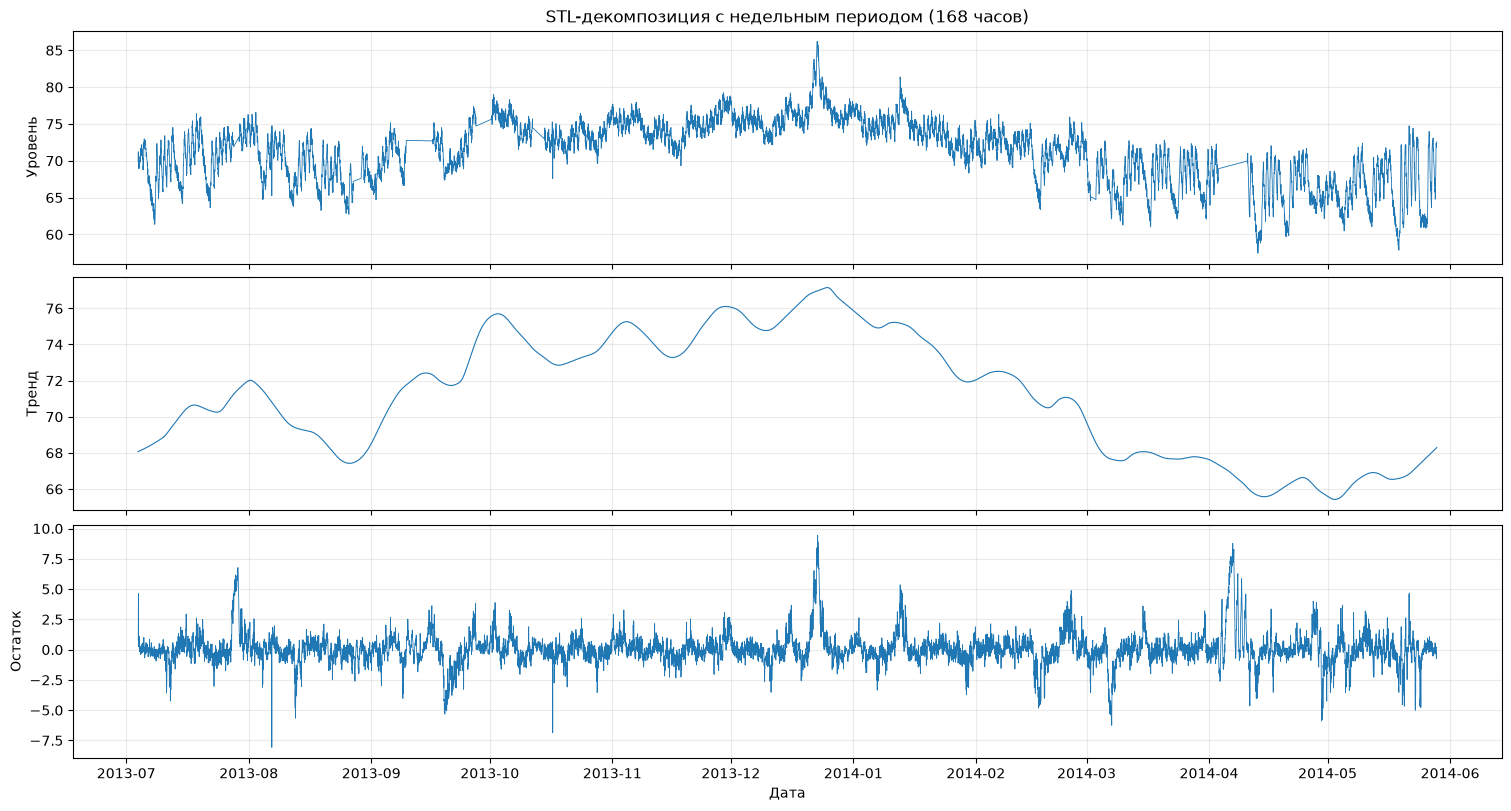

In [8]:
series_observed = df.set_index("timestamp")["value"].astype(float)
regular_series = series_observed.asfreq("h")
missing_hourly = int(regular_series.isna().sum())
regular_series = regular_series.interpolate(method="time").ffill().bfill()
regular_index = regular_series.index
observed_grid_idx = regular_index.get_indexer(df["timestamp"])
assert np.all(observed_grid_idx >= 0)
print("Часов в регулярной сетке:", len(regular_series))
print("Интерполированных часовых значений:", missing_hourly)
print("NAB оценивается на исходных точках:", len(df))

y_regular = regular_series.to_numpy(dtype=float)
stl_daily = STL(y_regular, period=24, robust=True).fit()
stl_weekly = STL(y_regular, period=168, robust=True).fit()

fig, axes = plt.subplots(3, 1, figsize=(15, 8), sharex=True, constrained_layout=True)
axes[0].plot(regular_index, y_regular, lw=0.6)
axes[0].set_ylabel("Уровень")
axes[0].set_title("STL-декомпозиция с недельным периодом (168 часов)")
axes[1].plot(regular_index, stl_weekly.trend, lw=0.8)
axes[1].set_ylabel("Тренд")
axes[2].plot(regular_index, stl_weekly.resid, lw=0.6)
axes[2].set_ylabel("Остаток")
axes[2].set_xlabel("Дата")
plt.show()

## 5. Собственная реализация NAB Score

NAB оценивает **срабатывания**, а не точечные `precision / recall / F1`. Первое обнаружение внутри аномального окна получает вклад, зависящий от времени: раннее срабатывание оценивается выше позднего. За каждое срабатывание вне окон добавляется отрицательный вклад, зависящий от расстояния до предыдущего окна. Пропущенное окно штрафуется как FN. Первые 15% точек (но не более 750 при стандартных параметрах) считаются probationary и не оцениваются.

Для взвешивания используется scaled sigmoid оригинального NAB:

\[
S(x)=2\frac{1}{1+e^{5x}}-1.
\]

После суммирования вкладов результат нормируется так, чтобы нулевой детектор имел 0, а идеальный — 100. Веса стандартного профиля: `tpWeight=1.0`, `fpWeight=0.11`, `fnWeight=1.0`. Реализация адаптирует код `nab/sweeper.py` к одному датасету.

In [9]:
NAB_PROFILES = {
    "standard": {"tpWeight": 1.0, "fpWeight": 0.11, "fnWeight": 1.0},
    "reward_low_FP_rate": {"tpWeight": 1.0, "fpWeight": 0.22, "fnWeight": 1.0},
    "reward_low_FN_rate": {"tpWeight": 1.0, "fpWeight": 0.11, "fnWeight": 2.0},
}


def scaled_sigmoid(relative_position):
    """Scaled sigmoid из оригинального NAB; relative_position может быть массивом."""
    x = np.asarray(relative_position, dtype=float)
    with np.errstate(over="ignore", invalid="ignore"):
        result = 2.0 / (1.0 + np.exp(np.clip(5.0 * x, -700, 700))) - 1.0
    result = np.where(x > 3.0, -1.0, result)
    return float(result) if result.ndim == 0 else result


def prepare_nab_points(timestamps, windows, profile="standard", probationary_percent=0.15):
    """Подготовить оконные веса и позиции по логике NAB Sweeper.calcSweepScore."""
    if profile not in NAB_PROFILES:
        raise ValueError(f"Неизвестный профиль NAB: {profile}")
    ts = pd.Series(pd.to_datetime(timestamps)).reset_index(drop=True)
    n = len(ts)
    window_id = np.full(n, -1, dtype=int)
    tp_contribution = np.full(n, np.nan, dtype=float)
    fp_contribution = np.zeros(n, dtype=float)
    window_edges = []

    max_tp = scaled_sigmoid(-1.0)
    for j, (start, end) in enumerate(windows):
        start, end = pd.Timestamp(start), pd.Timestamp(end)
        left_matches = np.flatnonzero((ts == start).to_numpy())
        right_matches = np.flatnonzero((ts == end).to_numpy())
        if len(left_matches) != 1 or len(right_matches) != 1:
            raise ValueError(f"Границы окна должны встречаться ровно один раз: {start} — {end}")
        left, right = int(left_matches[0]), int(right_matches[0])
        if right < left or np.any(window_id[left:right + 1] != -1):
            raise ValueError("Окна упорядочены неверно или пересекаются")
        window_id[left:right + 1] = j
        width = float(right - left + 1)
        positions = -(right - np.arange(left, right + 1) + 1) / width
        tp_contribution[left:right + 1] = (
            scaled_sigmoid(positions) / max_tp * NAB_PROFILES[profile]["tpWeight"]
        )
        window_edges.append((left, right, int(right - left + 1)))

    probationary_length = int(min(np.floor(probationary_percent * n), probationary_percent * 5000))
    scorable = np.arange(n) >= probationary_length

    previous_right, previous_width = None, None
    for i in range(n):
        if window_id[i] >= 0:
            j = window_id[i]
            if i == window_edges[j][1]:
                previous_right = i
                previous_width = window_edges[j][2]
            continue
        if previous_right is None:
            # До первого окна NAB assigns a full false-positive penalty.
            relative_position = 4.0
        else:
            relative_position = abs(previous_right - i) / float(max(previous_width - 1, 1))
        fp_contribution[i] = scaled_sigmoid(relative_position) * NAB_PROFILES[profile]["fpWeight"]

    return {
        "window_id": window_id,
        "tp_contribution": tp_contribution,
        "fp_contribution": fp_contribution,
        "scorable": scorable,
        "weights": NAB_PROFILES[profile],
        "window_edges": window_edges,
        "probationary_length": probationary_length,
    }


def score_nab_threshold(anomaly_scores, threshold, timestamps, windows, profile="standard"):
    """Нормированный NAB Score для заданного порога непрерывного anomaly score."""
    points = prepare_nab_points(timestamps, windows, profile, PROBATIONARY_PERCENT)
    scores = np.asarray(anomaly_scores, dtype=float)
    if len(scores) != len(points["window_id"]):
        raise ValueError("Длина anomaly_scores не совпадает с количеством наблюдений")
    if not np.isfinite(scores).all():
        raise ValueError("anomaly_scores содержат NaN или бесконечные значения")
    detected = (scores >= threshold) & points["scorable"]
    weights = points["weights"]
    raw_score = float(points["fp_contribution"][detected & (points["window_id"] < 0)].sum())
    detected_windows = 0
    for j in range(len(windows)):
        in_window = detected & (points["window_id"] == j)
        if in_window.any():
            # Внутри окна засчитывается максимальный вклад — это самое раннее обнаружение.
            raw_score += float(np.nanmax(points["tp_contribution"][in_window]))
            detected_windows += 1
        else:
            raw_score -= weights["fnWeight"]
    null_score = -weights["fnWeight"] * len(windows)
    perfect_score = weights["tpWeight"] * len(windows)
    normalized = 100.0 * (raw_score - null_score) / (perfect_score - null_score)
    return {
        "NAB Score": float(normalized), "raw_score": float(raw_score),
        "alerts": int(detected.sum()),
        "false_positives": int(np.sum(detected & (points["window_id"] < 0))),
        "windows_detected": int(detected_windows),
        "windows_missed": int(len(windows) - detected_windows),
    }


def direct_reference_nab_score(binary_predictions, timestamps, windows, profile="standard"):
    """Независимый прямой пересчёт по формулам оригинального NAB Sweeper."""
    import math

    # Намеренно отдельная реализация sigmoid; функция scaled_sigmoid выше не вызывается.
    def reference_scaled_sigmoid(relative_position):
        if relative_position > 3.0:
            return -1.0
        return 2.0 / (1.0 + math.exp(5.0 * float(relative_position))) - 1.0

    ts = pd.Series(pd.to_datetime(timestamps)).reset_index(drop=True)
    pred = np.asarray(binary_predictions, dtype=bool).copy()
    if len(pred) != len(ts):
        raise ValueError("Размер предсказаний и временных меток различается")
    weights = NAB_PROFILES[profile]
    probation = int(min(np.floor(PROBATIONARY_PERCENT * len(ts)), PROBATIONARY_PERCENT * 5000))
    pred[:probation] = False
    event_mask = np.full(len(ts), -1, dtype=int)
    edges = []
    for j, (start, end) in enumerate(windows):
        left = int(np.flatnonzero((ts == pd.Timestamp(start)).to_numpy())[0])
        right = int(np.flatnonzero((ts == pd.Timestamp(end)).to_numpy())[0])
        event_mask[left:right + 1] = j
        edges.append((left, right, right - left + 1))

    raw = 0.0
    fp_count = 0
    for j, (left, right, width) in enumerate(edges):
        hits = np.flatnonzero(pred[left:right + 1])
        if len(hits) == 0:
            raw -= weights["fnWeight"]
        else:
            first_hit = left + int(hits[0])
            relative = -(right - first_hit + 1) / float(width)
            raw += reference_scaled_sigmoid(relative) / reference_scaled_sigmoid(-1.0) * weights["tpWeight"]

    previous_right, previous_width = None, None
    for i in range(len(ts)):
        if event_mask[i] >= 0:
            j = event_mask[i]
            if i == edges[j][1]:
                previous_right, previous_width = i, edges[j][2]
            continue
        if pred[i]:
            if previous_right is None:
                relative = 4.0
            else:
                relative = abs(previous_right - i) / float(max(previous_width - 1, 1))
            raw += reference_scaled_sigmoid(relative) * weights["fpWeight"]
            fp_count += 1

    null_score = -weights["fnWeight"] * len(windows)
    perfect_score = weights["tpWeight"] * len(windows)
    return {
        "NAB Score": 100.0 * (raw - null_score) / (perfect_score - null_score),
        "raw_score": raw, "false_positives": fp_count,
    }


def optimize_nab_threshold(anomaly_scores, timestamps, windows, profile="standard"):
    """Перебор всех уникальных порогов алгоритмом sweep; возвращает лучший порог и кривую."""
    points = prepare_nab_points(timestamps, windows, profile, PROBATIONARY_PERCENT)
    scores = np.asarray(anomaly_scores, dtype=float).copy()
    if len(scores) != len(points["window_id"]):
        raise ValueError("Длина anomaly_scores не совпадает с количеством наблюдений")
    finite = np.isfinite(scores)
    replacement = float(np.min(scores[finite])) if finite.any() else 0.0
    scores[~finite] = replacement
    eligible = np.flatnonzero(points["scorable"])
    order = np.argsort(scores[eligible])[::-1]
    sorted_indices = eligible[order]

    window_id = points["window_id"]
    tp_contribution = points["tp_contribution"]
    fp_contribution = points["fp_contribution"]
    weights = points["weights"]
    null_score = -weights["fnWeight"] * len(windows)
    perfect_score = weights["tpWeight"] * len(windows)
    denom = perfect_score - null_score
    event_best = np.full(len(windows), -weights["fnWeight"], dtype=float)
    raw_score = float(null_score)
    best = {"threshold": np.inf, "NAB Score": 0.0, "raw_score": float(null_score),
            "alerts": 0, "false_positives": 0, "windows_detected": 0, "windows_missed": len(windows)}
    curve = [{"threshold": np.inf, "NAB Score": 0.0, "alerts": 0}]
    pos = alerts_so_far = fp_so_far = 0
    while pos < len(sorted_indices):
        value = scores[sorted_indices[pos]]
        end = pos + 1
        while end < len(sorted_indices) and scores[sorted_indices[end]] == value:
            end += 1
        group = sorted_indices[pos:end]
        outside = window_id[group] < 0
        if outside.any():
            raw_score += float(fp_contribution[group[outside]].sum())
            fp_so_far += int(outside.sum())
        inside = group[~outside]
        for j in np.unique(window_id[inside]):
            event_values = tp_contribution[inside[window_id[inside] == j]]
            new_best = max(event_best[j], float(np.nanmax(event_values)))
            raw_score += new_best - event_best[j]
            event_best[j] = new_best
        alerts_so_far += len(group)
        normalized = 100.0 * (raw_score - null_score) / denom
        detected_windows = int(np.sum(event_best > -weights["fnWeight"]))
        curve.append({"threshold": float(value), "NAB Score": float(normalized), "alerts": int(alerts_so_far)})
        if normalized > best["NAB Score"] + 1e-12:
            best = {"threshold": float(value), "NAB Score": float(normalized),
                    "raw_score": float(raw_score), "alerts": int(alerts_so_far),
                    "false_positives": int(fp_so_far), "windows_detected": detected_windows,
                    "windows_missed": len(windows) - detected_windows}
        pos = end

    if np.isfinite(best["threshold"]):
        independent = score_nab_threshold(scores, best["threshold"], timestamps, windows, profile)
        assert abs(independent["NAB Score"] - best["NAB Score"]) < 1e-8, (best, independent)
    best["curve"] = pd.DataFrame(curve)
    return best

print("NAB Score функции определены.")

NAB Score функции определены.


### 5.1 Проверка правильности NAB Score

Проверяем контрольные сценарии, а также сравниваем расчёт по порогу с отдельной прямой реализацией формулы. Это важнее, чем просто получить высокий Score: ошибка в нормализации или штрафах может искусственно завысить результат.

In [10]:
points_check = prepare_nab_points(df["timestamp"], anomaly_windows, NAB_PROFILE, PROBATIONARY_PERCENT)
no_alert_score = score_nab_threshold(np.zeros(len(df)), 1.1, df["timestamp"], anomaly_windows, NAB_PROFILE)

perfect_binary = np.zeros(len(df), dtype=bool)
for start, _ in anomaly_windows:
    perfect_binary[np.flatnonzero((df["timestamp"] == start).to_numpy())[0]] = True
perfect_reference = direct_reference_nab_score(perfect_binary, df["timestamp"], anomaly_windows, NAB_PROFILE)
perfect_score = score_nab_threshold(perfect_binary.astype(float), 0.5, df["timestamp"], anomaly_windows, NAB_PROFILE)

assert abs(no_alert_score["NAB Score"]) < 1e-10, no_alert_score
assert abs(perfect_score["NAB Score"] - 100.0) < 1e-10, perfect_score
assert abs(perfect_score["NAB Score"] - perfect_reference["NAB Score"]) < 1e-10

# Детерминированные граничные сценарии: до первого окна, на правой границе
# окна и сразу после закрытия окна. Проверяем прямое сравнение с отдельной формулой.
boundary_cases = {}
first_left = points_check["window_edges"][0][0]
first_right = points_check["window_edges"][0][1]
second_right = points_check["window_edges"][1][1]
for case_name, index in [
    ("до первого окна", max(points_check["probationary_length"], first_left - 1)),
    ("правая граница окна", first_right),
    ("сразу после окна", first_right + 1),
    ("правая граница второго окна", second_right),
]:
    mask = np.zeros(len(df), dtype=bool)
    mask[index] = True
    evaluated = score_nab_threshold(mask.astype(float), 0.5, df["timestamp"], anomaly_windows, NAB_PROFILE)
    referenced = direct_reference_nab_score(mask, df["timestamp"], anomaly_windows, NAB_PROFILE)
    assert abs(evaluated["NAB Score"] - referenced["NAB Score"]) < 1e-8, (case_name, evaluated, referenced)
    boundary_cases[case_name] = round(evaluated["NAB Score"], 6)

# Сравнение по случайным маскам с независимым прямым оценщиком.
rng = np.random.default_rng(RANDOM_STATE)
for test_id in range(25):
    mask = rng.random(len(df)) < rng.uniform(0.0002, 0.01)
    threshold_score = score_nab_threshold(mask.astype(float), 0.5, df["timestamp"], anomaly_windows, NAB_PROFILE)
    reference_score = direct_reference_nab_score(mask, df["timestamp"], anomaly_windows, NAB_PROFILE)
    assert abs(threshold_score["NAB Score"] - reference_score["NAB Score"]) < 1e-8

print("Нулевой детектор:", no_alert_score)
print("Идеальный детектор:", perfect_score)
print("Граничные проверки:", boundary_cases)
print("Проверок со случайными масками пройдено: 25 из 25")
print("NAB Score: реализация совпадает с независимо написанным прямым пересчётом.")

Нулевой детектор: {'NAB Score': 0.0, 'raw_score': -2.0, 'alerts': 0, 'false_positives': 0, 'windows_detected': 0, 'windows_missed': 2}
Идеальный детектор: {'NAB Score': 100.0, 'raw_score': 2.0, 'alerts': 2, 'false_positives': 0, 'windows_detected': 2, 'windows_missed': 0}
Граничные проверки: {'до первого окна': -2.75, 'правая граница окна': 25.17451, 'сразу после окна': -0.018991, 'правая граница второго окна': 25.17451}
Проверок со случайными масками пройдено: 25 из 25
NAB Score: реализация совпадает с независимо написанным прямым пересчётом.


## 6. Формирование сигналов аномальности

Каждый детектор формирует непрерывный `anomaly score`: чем он выше, тем подозрительнее точка. В отличие от стандартного практикума, метрики `precision / recall / F1` не используются для выбора метода — ниже все методы сравниваются по NAB Score.

### 6.1 Классические глобальные статистические методы

Три базовых правила из практикума рассмотрим отдельными ячейками, чтобы было проще экспериментировать с каждым сигналом.

In [11]:
y = df["value"].to_numpy(dtype=float)
s = df["value"].astype(float)
raw_scores = {}

#### 6.1.1 Z-score

In [12]:
mean_y, std_y = float(np.mean(y)), float(np.std(y))
raw_scores["Z-score (global)"] = np.abs(y - mean_y) / (std_y + 1e-9)
print("Глобальный Z-score построен; mean=", round(mean_y, 4), "; std=", round(std_y, 4))

Глобальный Z-score построен; mean= 71.2424 ; std= 4.2472


#### 6.1.2 Modified Z-score на основе MAD

In [13]:
median_y = float(np.median(y))
mad_y = float(np.median(np.abs(y - median_y))) * 1.4826
raw_scores["Modified Z-score (MAD)"] = np.abs(y - median_y) / (mad_y + 1e-9)
print("Modified Z-score построен; median=", round(median_y, 4), "; robust scale=", round(mad_y, 4))

Modified Z-score построен; median= 71.8585 ; robust scale= 4.3543


#### 6.1.3 Межквартильный размах (IQR)

In [14]:
q1, q3 = np.quantile(y, [0.25, 0.75])
iqr = q3 - q1
raw_scores["IQR"] = np.maximum(np.maximum(q1 - y, y - q3), 0.0) / (iqr + 1e-9)
print("IQR-сигнал построен; Q1=", round(q1, 4), "; Q3=", round(q3, 4), "; IQR=", round(iqr, 4))

IQR-сигнал построен; Q1= 68.3694 ; Q3= 74.431 ; IQR= 6.0615


### 6.2 Скользящие методы и влияние пропусков

Для обычных скользящих сигналов baseline сдвинут на один шаг (`shift(1)`), поэтому само текущее значение не входит в диапазон. Расчёт ведётся на почасовой сетке. Важно: исходная сетка содержит длинные разрывы, а линейная интерполяция через пропуски использует правую границу разрыва. Поэтому основные результаты — ретроспективный эксперимент, а не полностью потоковая оценка. Ниже добавлен контрольный вариант, в котором разрывы заполняются только последним известным значением (`forward-fill`); он позволяет проверить чувствительность NAB Score к этому решению.


In [15]:
reg = regular_series.astype(float)
reg_prev = reg.shift(1)

roll_mean_24 = reg_prev.rolling(24, min_periods=12).mean()
roll_std_24 = reg_prev.rolling(24, min_periods=12).std()
score_roll_sigma = np.abs(reg - roll_mean_24) / (roll_std_24 + 0.08)
raw_scores["Rolling 3-sigma score (24h baseline)"] = np.nan_to_num(
    score_roll_sigma.to_numpy()[observed_grid_idx], nan=0.0, posinf=0.0, neginf=0.0
)

for window_hours in [168, 336, 720]:
    q_low = reg_prev.rolling(window_hours, min_periods=max(24, window_hours // 4)).quantile(0.10)
    q_high = reg_prev.rolling(window_hours, min_periods=max(24, window_hours // 4)).quantile(0.90)
    excursion = np.maximum(np.maximum(q_low - reg, reg - q_high), 0.0)
    raw_scores[f"Rolling quantile ({window_hours}h)"] = np.nan_to_num(
        excursion.to_numpy()[observed_grid_idx], nan=0.0, posinf=0.0, neginf=0.0
    )

# Контроль чувствительности: заполнение только прошлым наблюдением, без линейной
# интерполяции через разрыв с использованием будущей правой границы.
reg_ffill = series_observed.asfreq("h").ffill()
reg_ffill_prev = reg_ffill.shift(1)
q_low_ffill = reg_ffill_prev.rolling(168, min_periods=42).quantile(0.10)
q_high_ffill = reg_ffill_prev.rolling(168, min_periods=42).quantile(0.90)
excursion_ffill = np.maximum(np.maximum(q_low_ffill - reg_ffill, reg_ffill - q_high_ffill), 0.0)
raw_scores["Rolling quantile (168h, forward-fill)"] = np.nan_to_num(
    excursion_ffill.to_numpy()[observed_grid_idx], nan=0.0, posinf=0.0, neginf=0.0
)

roll_median = reg_prev.rolling(168, min_periods=42).median()
def _mad_window(a):
    med = np.median(a)
    return 1.4826 * np.median(np.abs(a - med))
roll_mad = reg_prev.rolling(168, min_periods=42).apply(_mad_window, raw=True)
robust_rolling_score = np.abs(reg - roll_median) / (roll_mad + 0.08)
raw_scores["Rolling robust MAD (168h)"] = np.nan_to_num(
    robust_rolling_score.to_numpy()[observed_grid_idx], nan=0.0, posinf=0.0, neginf=0.0
)
print("Добавлено скользящих сигналов; текущее наблюдение не входит в baseline.")

Добавлено скользящих сигналов; текущее наблюдение не входит в baseline.


### 6.3 STL-остатки

Отклонение от тренда и сезонного шаблона может выявлять контекстные аномалии, незаметные по глобальному среднему. При интерпретации учитываем оговорку об интерполяции длинных пропусков из раздела 4.1.

In [16]:
def robust_scale(values):
    values = np.asarray(values, dtype=float)
    med = np.nanmedian(values)
    scale = 1.4826 * np.nanmedian(np.abs(values - med))
    if not np.isfinite(scale) or scale < 1e-9:
        scale = np.nanstd(values) + 1e-9
    return float(scale)

raw_scores["STL residual (daily)"] = np.abs(stl_daily.resid[observed_grid_idx]) / robust_scale(stl_daily.resid)
raw_scores["STL residual (weekly)"] = np.abs(stl_weekly.resid[observed_grid_idx]) / robust_scale(stl_weekly.resid)
print("Добавлены STL-остатки с суточным и недельным периодом.")

Добавлены STL-остатки с суточным и недельным периодом.


### 6.4 Детекторы без учителя: Isolation Forest, LOF, One-Class SVM и PCA-реконструкция

Чтобы загрязнение обучающей выборки аномалиями было меньше, алгоритмы обучаются на участке до начала первого размеченного окна. Признаки включают уровень, изменение и исторические скользящие характеристики. Для оценки Score модель выдаёт непрерывную величину, а не собственный бинарный класс.

In [17]:
feature_grid = pd.DataFrame(index=regular_index)
feature_grid["value"] = reg
feature_grid["delta_1"] = reg.diff()
feature_grid["delta_24"] = reg - reg.shift(24)
feature_grid["rolling_mean_24"] = reg_prev.rolling(24, min_periods=1).mean()
feature_grid["rolling_std_24"] = reg_prev.rolling(24, min_periods=2).std()
feature_grid["rolling_median_168"] = reg_prev.rolling(168, min_periods=1).median()
feature_grid = feature_grid.replace([np.inf, -np.inf], np.nan).fillna(0.0)

first_window_start = anomaly_windows[0][0]
train_mask_grid = feature_grid.index < first_window_start
scaler_ml = RobustScaler()
X_train = scaler_ml.fit_transform(feature_grid.loc[train_mask_grid])
X_all = scaler_ml.transform(feature_grid)
print("Размер матрицы признаков:", feature_grid.shape, "; обучающий участок:", int(train_mask_grid.sum()), "часов")

Размер матрицы признаков: (7888, 6) ; обучающий участок: 3943 часов


#### 6.4.1 Isolation Forest

In [18]:
iforest = IsolationForest(n_estimators=250, contamination="auto", random_state=RANDOM_STATE, n_jobs=-1)
iforest.fit(X_train)
raw_scores["Isolation Forest"] = -iforest.score_samples(X_all)[observed_grid_idx]
print("Isolation Forest: сигнал добавлен.")

Isolation Forest: сигнал добавлен.


#### 6.4.2 Local Outlier Factor (LOF)

In [19]:
lof = LocalOutlierFactor(n_neighbors=25, novelty=True, contamination="auto", n_jobs=-1)
lof.fit(X_train)
raw_scores["Local Outlier Factor"] = -lof.score_samples(X_all)[observed_grid_idx]
print("LOF: сигнал добавлен.")

LOF: сигнал добавлен.


#### 6.4.3 One-Class SVM

In [20]:
ocsvm = OneClassSVM(kernel="rbf", nu=0.02, gamma="scale")
ocsvm.fit(X_train)
raw_scores["One-Class SVM"] = -ocsvm.decision_function(X_all).ravel()[observed_grid_idx]
print("One-Class SVM: сигнал добавлен.")

One-Class SVM: сигнал добавлен.


#### 6.4.4 PCA-реконструкция

In [21]:
pca = PCA(n_components=0.95, svd_solver="full", random_state=RANDOM_STATE)
pca.fit(X_train)
X_reconstructed = pca.inverse_transform(pca.transform(X_all))
pca_error = np.mean((X_all - X_reconstructed) ** 2, axis=1)
raw_scores["PCA reconstruction error"] = pca_error[observed_grid_idx]
print(f"PCA: оставлено компонент = {pca.n_components_}; сигнал реконструкционной ошибки добавлен.")

PCA: оставлено компонент = 4; сигнал реконструкционной ошибки добавлен.


### 6.5 Прогнозные детекторы

Прогнозная ошибка — это расстояние между реальным значением и прогнозом на следующий час. Модели обучаются на периоде до первого аномального окна, затем дают one-step-ahead оценки. Это адаптация прогнозного блока исходной практики к задаче детектирования.

#### 6.5.1 SARIMAX: one-step prediction residual

In [22]:
train_regular = reg.loc[reg.index < first_window_start]
sarimax_score_added = False
try:
    sarimax_train = SARIMAX(
        train_regular, order=(1, 0, 1), seasonal_order=(1, 0, 0, 24),
        enforce_stationarity=False, enforce_invertibility=False
    ).fit(disp=False, maxiter=60)
    # Повторная фильтрация использует зафиксированные параметры; прогноз для t основан на прошлых наблюдениях.
    sarimax_full = SARIMAX(
        reg, order=(1, 0, 1), seasonal_order=(1, 0, 0, 24),
        enforce_stationarity=False, enforce_invertibility=False
    ).filter(sarimax_train.params)
    forecast_obj = sarimax_full.get_prediction(start=0, end=len(reg) - 1, dynamic=False)
    forecast_mean = np.asarray(forecast_obj.predicted_mean, dtype=float)
    forecast_se = np.sqrt(np.maximum(np.asarray(forecast_obj.var_pred_mean, dtype=float), 1e-6))
    forecast_residual_score = np.abs(y_regular - forecast_mean) / (forecast_se + 0.08)
    raw_scores["SARIMAX one-step residual"] = forecast_residual_score[observed_grid_idx]
    sarimax_score_added = True
    print("SARIMAX обучена; сигнал добавлен. Порядок: (1,0,1) × (1,0,0,24).")
except Exception as exc:
    print("SARIMAX не удалось обучить в этой среде; остальные методы продолжают работу.")
    print(type(exc).__name__ + ":", str(exc)[:300])

SARIMAX обучена; сигнал добавлен. Порядок: (1,0,1) × (1,0,0,24).


#### 6.5.2 MLP autoregressive forecaster

In [23]:
# MLP one-step forecaster: набор из 24 лагов формируется только из прошлых значений.
lag_frame = pd.concat({f"lag_{k}": reg.shift(k) for k in range(1, 25)}, axis=1)
valid_lags = lag_frame.notna().all(axis=1)
mlp_train_mask = valid_lags & (lag_frame.index < first_window_start)
mlp_scaler = StandardScaler()
X_mlp_train = mlp_scaler.fit_transform(lag_frame.loc[mlp_train_mask])
X_mlp_all = np.zeros((len(lag_frame), lag_frame.shape[1]), dtype=float)
X_mlp_all[valid_lags.to_numpy()] = mlp_scaler.transform(lag_frame.loc[valid_lags])
y_mlp_train = reg.loc[mlp_train_mask].to_numpy()
mlp_forecaster = MLPRegressor(
    hidden_layer_sizes=(32, 16), activation="relu", solver="adam",
    max_iter=250, early_stopping=True, random_state=RANDOM_STATE,
    validation_fraction=0.1, n_iter_no_change=15
)
mlp_forecaster.fit(X_mlp_train, y_mlp_train)
mlp_pred = np.full(len(reg), np.nan, dtype=float)
mlp_pred[valid_lags.to_numpy()] = mlp_forecaster.predict(X_mlp_all[valid_lags.to_numpy()])
mlp_train_pred = mlp_forecaster.predict(X_mlp_train)
mlp_train_resid = y_mlp_train - mlp_train_pred
mlp_resid_scale = robust_scale(mlp_train_resid)
mlp_score = np.abs(reg.to_numpy() - mlp_pred) / (mlp_resid_scale + 1e-6)
mlp_score = np.nan_to_num(mlp_score, nan=0.0, posinf=0.0, neginf=0.0)
raw_scores["MLP autoregressive residual"] = mlp_score[observed_grid_idx]
print("MLP обучена; число итераций:", mlp_forecaster.n_iter_, "; масштаб ошибки по обучающему периоду:", round(mlp_resid_scale, 4))

MLP обучена; число итераций: 250 ; масштаб ошибки по обучающему периоду: 0.7325


#### 6.5.3 Сопоставление прогнозных anomaly score

Для наглядности переводим два прогнозных сигнала в процентильный ранг и сравниваем, где они дают высокий сигнал относительно остального ряда.

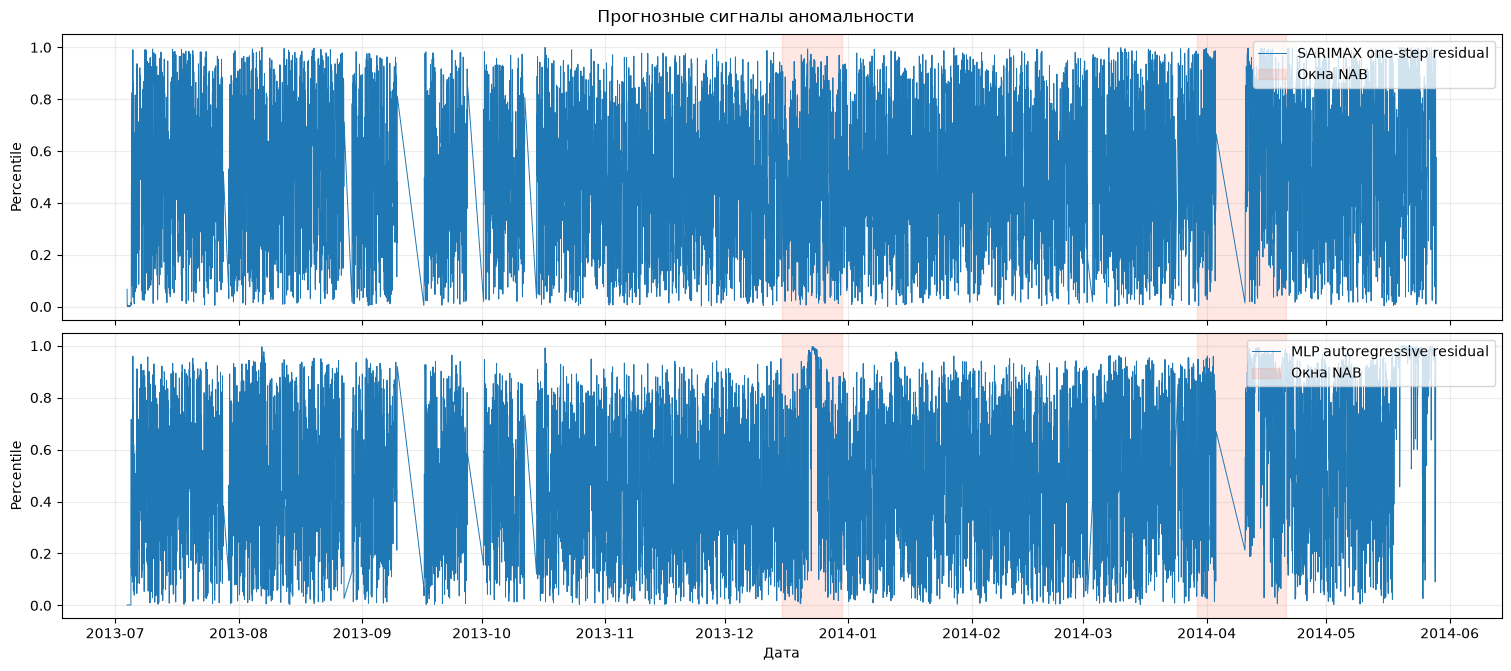

In [24]:
forecast_method_names = [name for name in ["SARIMAX one-step residual", "MLP autoregressive residual"] if name in raw_scores]
if forecast_method_names:
    fig, axes = plt.subplots(len(forecast_method_names), 1, figsize=(15, 3.3 * len(forecast_method_names)), sharex=True, constrained_layout=True)
    axes = np.atleast_1d(axes)
    for ax, name in zip(axes, forecast_method_names):
        score_rank = pd.Series(raw_scores[name]).rank(method="average", pct=True).to_numpy()
        ax.plot(df["timestamp"], score_rank, lw=0.7, label=name)
        for i, (start, end) in enumerate(anomaly_windows):
            ax.axvspan(start, end, color="tomato", alpha=0.15, label="Окна NAB" if i == 0 else None)
        ax.set_ylabel("Percentile")
        ax.legend(loc="upper right")
    axes[-1].set_xlabel("Дата")
    fig.suptitle("Прогнозные сигналы аномальности")
    plt.show()
else:
    print("Прогнозные модели не сформировали сигналы; этот график пропущен.")

### 6.6 LSTM-Autoencoder (опциональный метод из практикума)

Эта ячейка использует TensorFlow, если он установлен. Модель обучается на последовательностях до первого размеченного окна и выдаёт ошибку реконструкции. Если TensorFlow отсутствует, ноутбук не падает: метод явно пропускается, а остальные алгоритмы продолжают оцениваться.

In [25]:
import importlib.util
if importlib.util.find_spec("tensorflow") is None:
    print("TensorFlow не установлен — LSTM-Autoencoder пропущен; оценка остальных методов выполняется полностью.")
else:
    import tensorflow as tf
    from tensorflow.keras import layers, models
    tf.random.set_seed(RANDOM_STATE)
    seq_len = 24
    train_mean = float(reg.loc[reg.index < first_window_start].mean())
    train_std = float(reg.loc[reg.index < first_window_start].std()) + 1e-6
    norm_values = (reg.to_numpy(dtype=np.float32) - train_mean) / train_std
    seq = np.lib.stride_tricks.sliding_window_view(norm_values, seq_len).copy()
    seq_end_indices = np.arange(seq_len - 1, len(norm_values))
    train_seq_mask = regular_index[seq_end_indices] < first_window_start
    X_seq_train = seq[train_seq_mask, :, None]
    X_seq_all = seq[:, :, None]
    inp = layers.Input(shape=(seq_len, 1))
    encoded = layers.LSTM(16, activation="tanh")(inp)
    decoded = layers.RepeatVector(seq_len)(encoded)
    decoded = layers.LSTM(16, activation="tanh", return_sequences=True)(decoded)
    out = layers.TimeDistributed(layers.Dense(1))(decoded)
    lstm_ae = models.Model(inp, out)
    lstm_ae.compile(optimizer="adam", loss="mse")
    lstm_ae.fit(X_seq_train, X_seq_train, epochs=5, batch_size=128, shuffle=True, verbose=0)
    reconstruction = lstm_ae.predict(X_seq_all, batch_size=256, verbose=0)
    reconstruction_error = np.mean((X_seq_all - reconstruction) ** 2, axis=(1, 2))
    score_grid = np.zeros(len(reg), dtype=float)
    score_grid[seq_end_indices] = reconstruction_error
    raw_scores["LSTM Autoencoder"] = score_grid[observed_grid_idx]
    print("LSTM-Autoencoder обучен; окон в train:", len(X_seq_train), "; сигнал добавлен в сравнение.")

TensorFlow не установлен — LSTM-Autoencoder пропущен; оценка остальных методов выполняется полностью.


### 6.7 Проверка построенных сигналов

Проверяем длины, конечность значений и диапазоны. Сравнение рангов далее устраняет различия масштабов между статистическими, сезонными и ML-оценками.

In [26]:
signal_check = []
for name, values in raw_scores.items():
    arr = np.asarray(values, dtype=float)
    signal_check.append({
        "Метод": name,
        "Длина": len(arr),
        "Все значения конечны": bool(np.isfinite(arr).all()),
        "Минимум": float(np.min(arr)),
        "Максимум": float(np.max(arr)),
        "Уникальных значений": int(pd.Series(arr).nunique()),
    })
    assert len(arr) == len(df), f"Неправильная длина сигнала: {name}"
    assert np.isfinite(arr).all(), f"NaN или бесконечность в сигнале: {name}"
display(pd.DataFrame(signal_check))
print("Всего сигналов для сравнения:", len(raw_scores))

,Метод,Длина,Все значения конечны,Минимум,Максимум,Уникальных значений
0,Z-score (global),7267,True,2.249728e-04,3.527199,7267
1,Modified Z-score (MAD),7267,True,0.000000e+00,3.307069,7267
2,IQR,7267,True,0.000000e+00,1.945420,3635
3,Rolling 3-sigma score (24h baseline),7267,True,0.000000e+00,9.934895,7256
4,Rolling quantile (168h),7267,True,0.000000e+00,6.728032,2048
5,Rolling quantile (336h),7267,True,0.000000e+00,7.397465,1988
6,Rolling quantile (720h),7267,True,0.000000e+00,8.112322,1810
7,"Rolling quantile (168h, forward-fill)",7267,True,0.000000e+00,6.551952,2047
8,Rolling robust MAD (168h),7267,True,0.000000e+00,49.618290,7100
9,STL residual (daily),7267,True,1.064164e-04,18.054853,7267


Всего сигналов для сравнения: 17


## 7. Оптимизация порогов и сравнение по NAB Score

Каждый непрерывный сигнал переводится в процентильный ранг. Для каждого метода перебираются все уникальные пороги на оцениваемом участке; выбор лучшего порога основан только на NAB Score. Ансамбль объединяет ранги скользящего квантильного диапазона, MAD и недельного STL-остатка. Подбор на том же наборе с окнами NAB — эксперимент по поиску максимума для заданного датасета, не независимая валидация.

In [27]:
def rank_percentile(values):
    values = np.asarray(values, dtype=float)
    return pd.Series(values).rank(method="average", pct=True).to_numpy(dtype=float)

ranked_scores = {name: rank_percentile(values) for name, values in raw_scores.items()}
ensemble_components = [
    "Rolling quantile (336h)",
    "Modified Z-score (MAD)",
    "STL residual (weekly)",
]
ranked_scores["Ансамбль рангов (3 сигнала)"] = np.mean(
    [ranked_scores[name] for name in ensemble_components], axis=0
)

optimized = {}
comparison_rows = []
for method_name, scores in ranked_scores.items():
    result = optimize_nab_threshold(scores, df["timestamp"], anomaly_windows, profile=NAB_PROFILE)
    optimized[method_name] = result
    comparison_rows.append({k: v for k, v in {"Метод": method_name, **result}.items() if k != "curve"})

results_df = pd.DataFrame(comparison_rows).sort_values(
    ["NAB Score", "false_positives", "alerts"], ascending=[False, True, True]
).reset_index(drop=True)
display(results_df[["Метод", "NAB Score", "threshold", "raw_score", "alerts", "false_positives", "windows_detected", "windows_missed"]].round(5))

,Метод,NAB Score,threshold,raw_score,alerts,false_positives,windows_detected,windows_missed
0,Rolling quantile (168h),95.77042,0.99890,1.83082,6,0,2,0
1,"Rolling quantile (168h, forward-fill)",95.74487,0.99917,1.82979,4,0,2,0
2,Ансамбль рангов (3 сигнала),94.47644,0.99124,1.77906,23,0,2,0
3,Rolling quantile (336h),94.29935,0.99752,1.77197,19,0,2,0
4,Z-score (global),93.27801,0.99862,1.73112,11,0,2,0
5,IQR,93.27801,0.99862,1.73112,11,0,2,0
6,Modified Z-score (MAD),93.23020,0.99931,1.72921,6,0,2,0
7,Rolling quantile (720h),87.68184,0.99835,1.50727,13,2,2,0
8,STL residual (weekly),46.66263,0.99959,-0.13349,4,0,1,1
9,PCA reconstruction error,46.37067,0.99601,-0.14517,29,0,1,1


### 7.1 График сравнения NAB Score

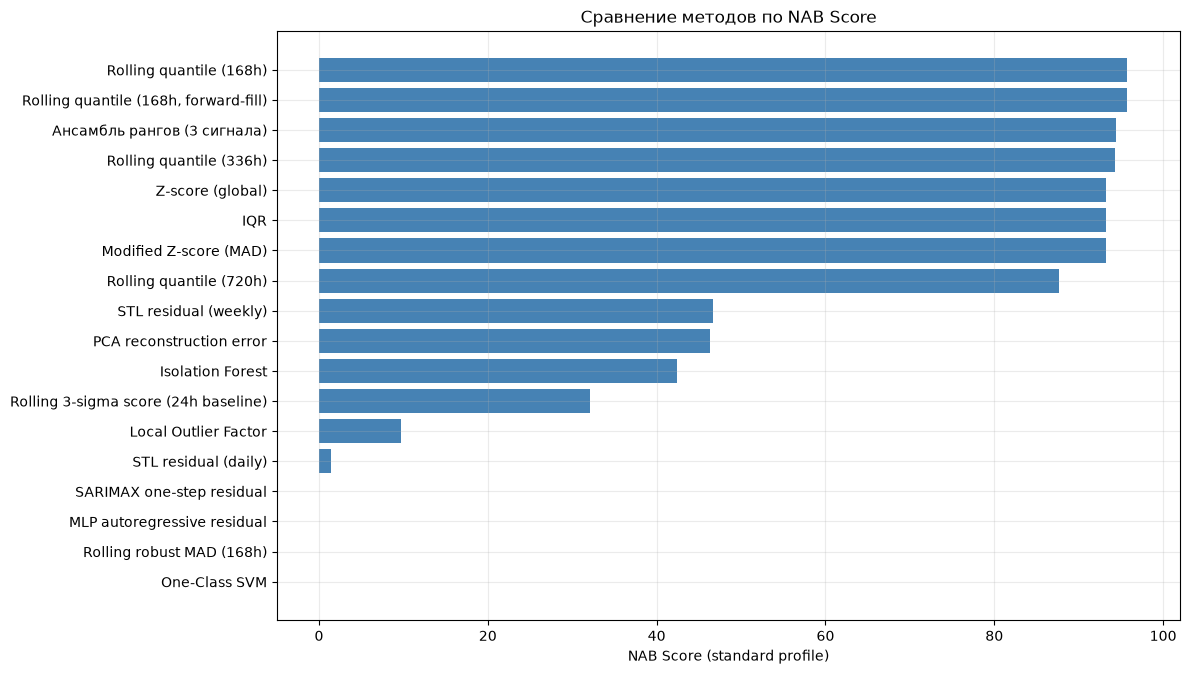

In [28]:
fig, ax = plt.subplots(figsize=(12, max(5, 0.38 * len(results_df))))
plot_df = results_df.sort_values("NAB Score", ascending=True)
ax.barh(plot_df["Метод"], plot_df["NAB Score"], color="steelblue")
ax.set_xlabel("NAB Score (standard profile)")
ax.set_title("Сравнение методов по NAB Score")
ax.set_xlim(min(-5, float(plot_df["NAB Score"].min()) - 2), 102)
plt.tight_layout()
plt.show()

### 7.2 Экспорт результатов эксперимента

In [29]:
EXPORT_PATH = Path("nab_ambient_temperature_score_comparison_verified.csv")
export_columns = ["Метод", "NAB Score", "threshold", "raw_score", "alerts", "false_positives", "windows_detected", "windows_missed"]
results_df[export_columns].to_csv(EXPORT_PATH, index=False, encoding="utf-8-sig")
print("CSV сохранён:", EXPORT_PATH.resolve())
display(results_df[export_columns].round({"NAB Score": 4, "threshold": 6, "raw_score": 5}))

CSV сохранён: D:\Projects\infosec-da-group\hw-4\nab_ambient_temperature_score_comparison_verified.csv


,Метод,NAB Score,threshold,raw_score,alerts,false_positives,windows_detected,windows_missed
0,Rolling quantile (168h),95.7704,0.998899,1.83082,6,0,2,0
1,"Rolling quantile (168h, forward-fill)",95.7449,0.999174,1.82979,4,0,2,0
2,Ансамбль рангов (3 сигнала),94.4764,0.991239,1.77906,23,0,2,0
3,Rolling quantile (336h),94.2994,0.997523,1.77197,19,0,2,0
4,Z-score (global),93.2780,0.998624,1.73112,11,0,2,0
5,IQR,93.2780,0.998624,1.73112,11,0,2,0
6,Modified Z-score (MAD),93.2302,0.999312,1.72921,6,0,2,0
7,Rolling quantile (720h),87.6818,0.998349,1.50727,13,2,2,0
8,STL residual (weekly),46.6626,0.999587,-0.13349,4,0,1,1
9,PCA reconstruction error,46.3707,0.996009,-0.14517,29,0,1,1


## 8. Лучший метод: порог, кривая Score и временная локализация

Лучший метод: Rolling quantile (168h)
NAB Score (standard): 95.7704
Порог: 0.99889913
Срабатываний в scorable-периоде: 6
Ложных срабатываний вне окон: 0
Обнаружено окон: 2 из 2
Независимая проверка Score: 95.77042056


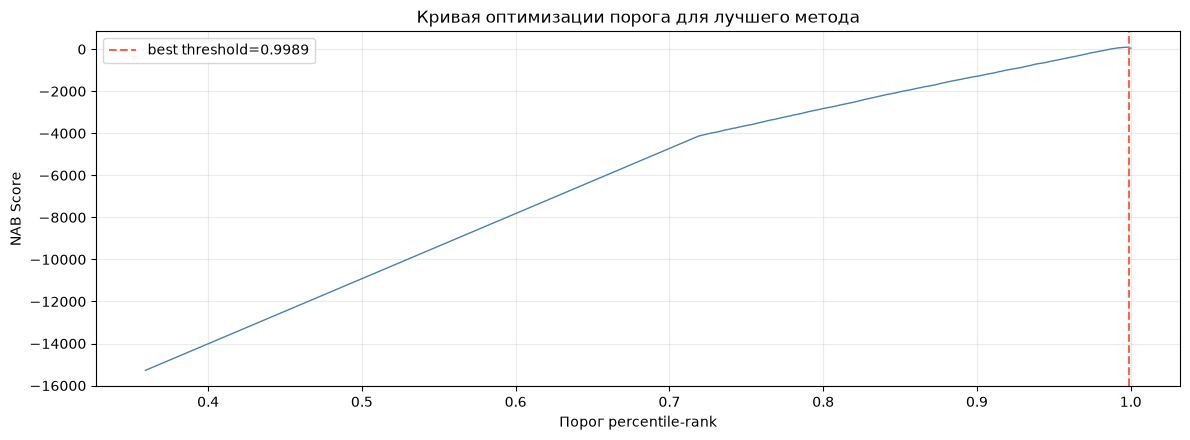

In [30]:
best_row = results_df.iloc[0]
best_method = str(best_row["Метод"])
best_result = optimized[best_method]
best_scores = ranked_scores[best_method]
best_threshold = float(best_result["threshold"])
points_best = prepare_nab_points(df["timestamp"], anomaly_windows, NAB_PROFILE, PROBATIONARY_PERCENT)
final_predictions = (best_scores >= best_threshold) & points_best["scorable"] if np.isfinite(best_threshold) else np.zeros(len(df), dtype=bool)

final_score_check = score_nab_threshold(best_scores, best_threshold, df["timestamp"], anomaly_windows, NAB_PROFILE)
reference_score_check = direct_reference_nab_score(final_predictions, df["timestamp"], anomaly_windows, NAB_PROFILE)
assert abs(final_score_check["NAB Score"] - best_result["NAB Score"]) < 1e-8
assert abs(final_score_check["NAB Score"] - reference_score_check["NAB Score"]) < 1e-8
print("Лучший метод:", best_method)
print(f"NAB Score ({NAB_PROFILE}): {final_score_check['NAB Score']:.4f}")
print(f"Порог: {best_threshold:.8f}")
print("Срабатываний в scorable-периоде:", final_score_check["alerts"])
print("Ложных срабатываний вне окон:", final_score_check["false_positives"])
print(f"Обнаружено окон: {final_score_check['windows_detected']} из {len(anomaly_windows)}")
print(f"Независимая проверка Score: {reference_score_check['NAB Score']:.8f}")

curve_df = best_result["curve"].dropna(subset=["NAB Score"]).copy()
curve_df = curve_df[np.isfinite(curve_df["threshold"])].sort_values("threshold")
fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.plot(curve_df["threshold"], curve_df["NAB Score"], lw=1.0, color="steelblue")
ax1.axvline(best_threshold, color="tomato", ls="--", label=f"best threshold={best_threshold:.4f}")
ax1.set_xlabel("Порог percentile-rank")
ax1.set_ylabel("NAB Score")
ax1.set_title("Кривая оптимизации порога для лучшего метода")
ax1.legend()
plt.tight_layout()
plt.show()

### 8.1 Все срабатывания на временном ряду

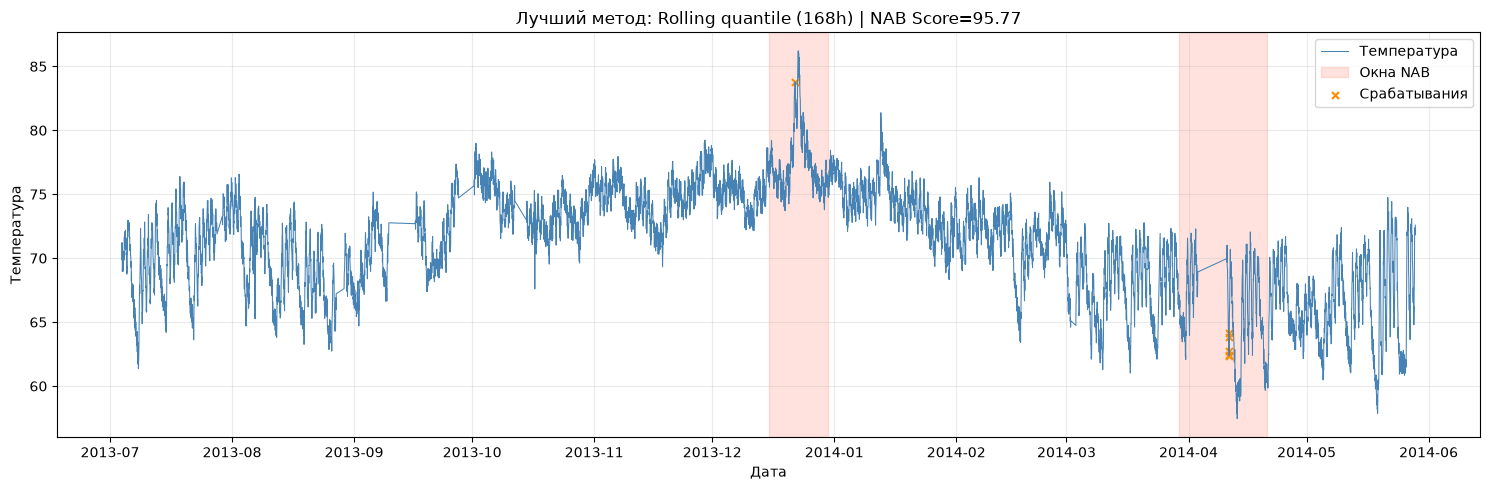

Первые срабатывания:


,timestamp,value
3702,2013-12-22 01:00:00,83.780995
6127,2014-04-11 04:00:00,64.155116
6128,2014-04-11 05:00:00,62.702991
6129,2014-04-11 06:00:00,63.839441
6130,2014-04-11 07:00:00,62.441949
6131,2014-04-11 08:00:00,62.371144


In [31]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(df["timestamp"], df["value"], lw=0.75, color="steelblue", label="Температура")
for i, (start, end) in enumerate(anomaly_windows):
    ax.axvspan(start, end, color="tomato", alpha=0.18, label="Окна NAB" if i == 0 else None)
alerts_df = df.loc[final_predictions]
ax.scatter(alerts_df["timestamp"], alerts_df["value"], color="darkorange", s=25, marker="x", label="Срабатывания")
ax.set(title=f"Лучший метод: {best_method} | NAB Score={final_score_check['NAB Score']:.2f}", xlabel="Дата", ylabel="Температура")
ax.legend()
plt.tight_layout()
plt.show()
print("Первые срабатывания:")
display(alerts_df[["timestamp", "value"]].head(20))

### 8.2 Проверка каждого аномального окна

In [32]:
event_rows = []
for j, (start, end) in enumerate(anomaly_windows):
    in_window = final_predictions & df["timestamp"].between(start, end, inclusive="both").to_numpy()
    alert_times = df.loc[in_window, "timestamp"]
    if len(alert_times):
        first_alert = alert_times.iloc[0]
        delay_hours = (first_alert - start).total_seconds() / 3600
        score_points = points_best["tp_contribution"][in_window]
        tp_contribution = float(np.max(score_points))
    else:
        first_alert, delay_hours, tp_contribution = pd.NaT, np.nan, np.nan
    event_rows.append({
        "Окно NAB": j + 1, "Начало": start, "Конец": end,
        "Точек в окне": int(df["timestamp"].between(start, end, inclusive="both").sum()),
        "Срабатываний": int(in_window.sum()), "Первое срабатывание": first_alert,
        "Задержка, ч": delay_hours, "Вклад TP": tp_contribution,
    })
event_results = pd.DataFrame(event_rows)
display(event_results)
assert event_results["Срабатываний"].gt(0).all(), "Как минимум одно окно не обнаружено выбранным порогом."

,Окно NAB,Начало,Конец,Точек в окне,Срабатываний,Первое срабатывание,"Задержка, ч",Вклад TP
0,1,2013-12-15 07:00:00,2013-12-30 09:00:00,363,1,2013-12-22 01:00:00,162.0,0.893875
1,2,2014-03-29 15:00:00,2014-04-20 22:00:00,363,5,2014-04-11 04:00:00,301.0,0.936942


## 9. Проверка стандартных профилей NAB

Разные прикладные профили меняют стоимость ложных тревог и пропусков. Здесь для лучшего сигнала отдельно оптимизируется порог под каждый профиль; поэтому значения показывают результат подстройки, а не сравнение единого рабочего порога.

In [33]:
profile_rows = []
profile_optimized = {}
for profile_name in NAB_PROFILES:
    result = optimize_nab_threshold(best_scores, df["timestamp"], anomaly_windows, profile=profile_name)
    profile_optimized[profile_name] = result
    profile_rows.append({k: v for k, v in {"Профиль": profile_name, **result}.items() if k != "curve"})
profile_results = pd.DataFrame(profile_rows)
display(profile_results[["Профиль", "NAB Score", "threshold", "alerts", "false_positives", "windows_detected", "windows_missed"]].round(5))

,Профиль,NAB Score,threshold,alerts,false_positives,windows_detected,windows_missed
0,standard,95.77042,0.9989,6,0,2,0
1,reward_low_FP_rate,95.77042,0.9989,6,0,2,0
2,reward_low_FN_rate,97.18028,0.9989,6,0,2,0


## 10. Дополнительная проверка прогнозирования (MAE/RMSE)

В исходной практике модели прогнозирования оцениваются отдельно от детекторов аномалий. Сравним на одном оценочном отрезке: наивный прогноз последним значением, сезонный наивный прогноз, константный mean-baseline по обучающему периоду, SARIMAX и авторегрессионный MLP. Дополнительно ниже обучается **опциональный LSTM-прогноз следующего значения**, если TensorFlow установлен. Эти метрики не подменяют NAB Score и не участвуют в выборе порога детектора.

In [34]:
# LSTM forecaster: прогнозирует следующее значение по 24 предыдущим часам.
# Модель обучается только на целевых точках до первого размеченного окна.
import importlib.util
lstm_forecast = None
lstm_forecast_added = False
if importlib.util.find_spec("tensorflow") is None:
    print("TensorFlow не установлен — LSTM forecasting пропущен; остальные прогнозы сравниваются.")
else:
    import tensorflow as tf
    from tensorflow.keras import layers, models, callbacks
    tf.random.set_seed(RANDOM_STATE)
    seq_len_forecast = 24
    values_forecast = reg.to_numpy(dtype=np.float32)
    forecast_train_end = float(reg.loc[reg.index < first_window_start].mean())
    forecast_train_scale = float(reg.loc[reg.index < first_window_start].std()) + 1e-6
    values_forecast_scaled = (values_forecast - forecast_train_end) / forecast_train_scale

    # Каждая последовательность содержит t-24,...,t-1, а target — значение в t.
    if len(values_forecast_scaled) <= seq_len_forecast:
        print("Недостаточно значений для обучения LSTM forecast.")
    else:
        all_sequences = np.lib.stride_tricks.sliding_window_view(
            values_forecast_scaled, seq_len_forecast
        )[:-1].copy()[..., None]
        target_values = values_forecast_scaled[seq_len_forecast:]
        target_indices = np.arange(seq_len_forecast, len(values_forecast_scaled))
        target_timestamps = regular_index[target_indices]
        train_seq_mask = target_timestamps < first_window_start
        X_lstm_train = all_sequences[train_seq_mask]
        y_lstm_train = target_values[train_seq_mask]

        tf.keras.backend.clear_session()
        lstm_forecaster = models.Sequential([
            layers.Input(shape=(seq_len_forecast, 1)),
            layers.LSTM(16, activation="tanh"),
            layers.Dense(1),
        ])
        lstm_forecaster.compile(optimizer="adam", loss="mse")
        early_stop = callbacks.EarlyStopping(
            monitor="val_loss", patience=5, restore_best_weights=True
        )
        lstm_forecaster.fit(
            X_lstm_train, y_lstm_train, epochs=40, batch_size=64,
            validation_split=0.1, shuffle=False, callbacks=[early_stop], verbose=0
        )
        pred_scaled = lstm_forecaster.predict(all_sequences, batch_size=256, verbose=0).ravel()
        lstm_forecast = np.full(len(reg), np.nan, dtype=float)
        lstm_forecast[target_indices] = pred_scaled * forecast_train_scale + forecast_train_end
        lstm_forecast_added = True
        print(
            "LSTM forecaster обучен; обучающих последовательностей:", len(X_lstm_train),
            "; эпох выполнено:", len(lstm_forecaster.history.history.get("loss", []))
        )

TensorFlow не установлен — LSTM forecasting пропущен; остальные прогнозы сравниваются.


In [35]:
# Проверка прогноза на исходных наблюдениях после начала первого аномального окна.
# Нужны 24 непрерывных фактических наблюдения до каждой точки оценки.
observed_timestamp_set = set(pd.to_datetime(df["timestamp"]))
has_24h_observed_history = np.array([
    all((t - pd.Timedelta(hours=k)) in observed_timestamp_set for k in range(1, 25))
    for t in df["timestamp"]
], dtype=bool)
forecast_eval_mask = (df["timestamp"] >= first_window_start).to_numpy() & has_24h_observed_history

grid_persistence = reg_ffill.shift(1).to_numpy()[observed_grid_idx]
grid_seasonal_naive = reg_ffill.shift(24).to_numpy()[observed_grid_idx]
train_mean_forecast = float(reg.loc[reg.index < first_window_start].mean())
forecast_candidates = {
    "Naive persistence (1h)": grid_persistence,
    "Seasonal naive (24h)": grid_seasonal_naive,
    "Mean baseline (training mean)": np.full(len(df), train_mean_forecast, dtype=float),
}
if sarimax_score_added:
    forecast_candidates["SARIMAX one-step"] = np.asarray(forecast_mean, dtype=float)[observed_grid_idx]
if "mlp_pred" in locals():
    forecast_candidates["MLP autoregressive"] = np.asarray(mlp_pred, dtype=float)[observed_grid_idx]
if lstm_forecast_added and lstm_forecast is not None:
    forecast_candidates["LSTM forecaster"] = np.asarray(lstm_forecast, dtype=float)[observed_grid_idx]

forecast_metric_rows = []
for model_name, prediction in forecast_candidates.items():
    prediction = np.asarray(prediction, dtype=float)
    valid = forecast_eval_mask & np.isfinite(prediction)
    errors = df.loc[valid, "value"].to_numpy(dtype=float) - prediction[valid]
    if len(errors) == 0:
        continue
    forecast_metric_rows.append({
        "Модель": model_name,
        "Число точек": int(len(errors)),
        "MAE": float(np.mean(np.abs(errors))),
        "RMSE": float(np.sqrt(np.mean(errors ** 2))),
    })
forecast_metrics_df = pd.DataFrame(forecast_metric_rows).sort_values("RMSE").reset_index(drop=True)
print("Оценочный период:", df.loc[forecast_eval_mask, "timestamp"].min(), "—", df.loc[forecast_eval_mask, "timestamp"].max())
print("Число исходных точек с полным 24-часовым контекстом:", int(forecast_eval_mask.sum()))
display(forecast_metrics_df.round({"MAE": 4, "RMSE": 4}))
assert len(forecast_metrics_df) >= 2, "Не удалось сравнить хотя бы два прогноза."


Оценочный период: 2013-12-15 07:00:00 — 2014-05-28 15:00:00
Число исходных точек с полным 24-часовым контекстом: 3631


,Модель,Число точек,MAE,RMSE
0,SARIMAX one-step,3631,0.7167,0.9016
1,Naive persistence (1h),3631,0.7440,0.9267
2,MLP autoregressive,3631,1.1057,1.8696
3,Seasonal naive (24h),3631,1.8714,2.6174
4,Mean baseline (training mean),3631,4.1473,5.2055


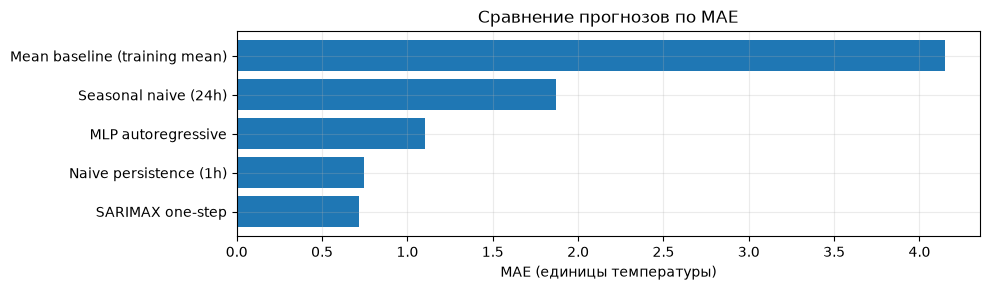

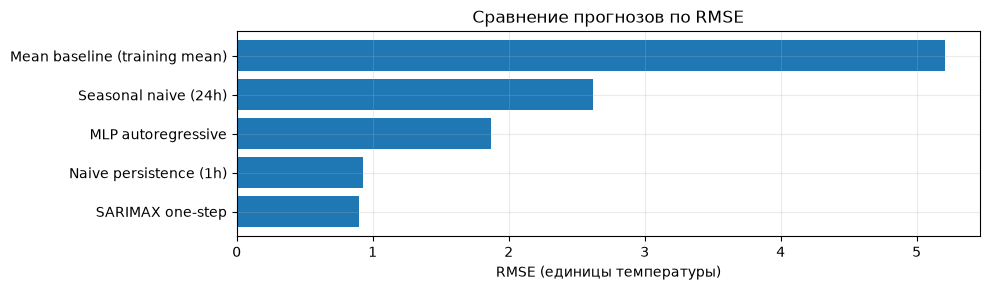

In [36]:
for metric in ["MAE", "RMSE"]:
    plot_df = forecast_metrics_df.sort_values(metric, ascending=True)
    fig, ax = plt.subplots(figsize=(10, max(3, 0.6 * len(plot_df))))
    ax.barh(plot_df["Модель"], plot_df[metric])
    ax.set_xlabel(f"{metric} (единицы температуры)")
    ax.set_title(f"Сравнение прогнозов по {metric}")
    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()


## 11. Итоговые выводы

In [37]:
print(f"1. В данных {len(df):,} измерений; временной диапазон: {df['timestamp'].min()} — {df['timestamp'].max()}.")
print(f"2. Официальная разметка NAB содержит {len(anomaly_windows)} аномальных окон.")
print(f"3. Наивысший протестированный NAB Score: {final_score_check['NAB Score']:.4f} ({NAB_PROFILE}), метод: {best_method}.")
print(f"4. Выбранный порог обнаруживает {final_score_check['windows_detected']} из {len(anomaly_windows)} окон; ложных срабатываний вне окон: {final_score_check['false_positives']}.")
print("5. Реализация сверена с независимым прямым расчётом и проверена на нулевом, идеальном и 25 случайных бинарных детекторах.")
print("6. Для признаков сезонности выполнена почасовая регуляризация; 621 отсутствующий час интерполирован, в том числе есть длительный разрыв внутри второго окна.")
print("7. Порог оптимизирован на этом же размеченном датасете: итоговый Score описывает результат настройки на данной разметке и не является независимой оценкой качества на новых данных.")
print("8. Линейная интерполяция через разрывы и percentile-rank по всему ряду делают оценку ретроспективной; нельзя считать её честным онлайн-бенчмарком.")
ffill_row = results_df.loc[results_df["Метод"] == "Rolling quantile (168h, forward-fill)"]
if not ffill_row.empty:
    ffill_score = float(ffill_row.iloc[0]["NAB Score"])
    print(f"9. Контроль без линейной интерполяции (forward-fill baseline) дал NAB Score {ffill_score:.4f}; основной результат зависит от предобработки лишь на {abs(final_score_check['NAB Score'] - ffill_score):.4f} пункта.")
print("10. Для реального потока нужны порог, заранее зафиксированный на обучающем/калибровочном периоде, и обработка пропусков, не использующая будущую правую границу разрыва.")
print("11. В отдельной секции сравниваются прогнозы по MAE/RMSE; эти метрики не подменяют NAB Score и не влияют на выбор детектора.")
print("12. Многомерный анализ исходного шаблона неприменим к этому CSV: доступна только одна числовая метрика температуры.")
print("13. NAB Score не заменяет анализ стоимости FP/FN; при другом профиле NAB может измениться оптимальный порог.")

1. В данных 7,267 измерений; временной диапазон: 2013-07-04 00:00:00 — 2014-05-28 15:00:00.
2. Официальная разметка NAB содержит 2 аномальных окон.
3. Наивысший протестированный NAB Score: 95.7704 (standard), метод: Rolling quantile (168h).
4. Выбранный порог обнаруживает 2 из 2 окон; ложных срабатываний вне окон: 0.
5. Реализация сверена с независимым прямым расчётом и проверена на нулевом, идеальном и 25 случайных бинарных детекторах.
6. Для признаков сезонности выполнена почасовая регуляризация; 621 отсутствующий час интерполирован, в том числе есть длительный разрыв внутри второго окна.
7. Порог оптимизирован на этом же размеченном датасете: итоговый Score описывает результат настройки на данной разметке и не является независимой оценкой качества на новых данных.
8. Линейная интерполяция через разрывы и percentile-rank по всему ряду делают оценку ретроспективной; нельзя считать её честным онлайн-бенчмарком.
9. Контроль без линейной интерполяции (forward-fill baseline) дал NAB Score

## Источники и методологические примечания

- Датасет: [ambient_temperature_system_failure.csv](https://github.com/numenta/NAB/blob/master/data/realKnownCause/ambient_temperature_system_failure.csv).
- Официальные аномальные окна: [labels/combined_windows.json](https://github.com/numenta/NAB/blob/master/labels/combined_windows.json).
- Оригинальная реализация скоринга: [nab/sweeper.py](https://github.com/numenta/NAB/blob/master/nab/sweeper.py), в особенности `scaledSigmoid`, `calcSweepScore` и `calcScoreByThreshold`.
- Описание идеи метрики: [Numenta Anomaly Benchmark](https://github.com/numenta/NAB).

**О применимости методов из шаблона:** отдельный многомерный анализ не выполняется, так как целевой CSV содержит только `timestamp` и одну числовую метрику `value`; для корреляционной матрицы и многомерного Isolation Forest нужны несколько синхронных рядов. В ноутбук добавлены интерактивный Plotly-график и самостоятельная проверка прогнозов по MAE/RMSE.

**Ограничения:** максимальный Score получен перебором порога по известной разметке именно этого файла. Такой результат нельзя переносить на неизвестные данные. Оценщик NAB работает с исходными временными метками и исходными точками CSV, а сезонные/прогнозные признаки используют почасовую сетку с 621 интерполированным часом. Во втором размеченном окне есть разрыв наблюдений длительностью 174 часа. Линейная интерполяция через него может использовать значение на правой границе для заполнения прошлых синтетических точек; поэтому добавлен контрольный скользящий метод с forward-fill. Кроме того, percent-rank нормируется по всему ряду, а порог подбирается по меткам этого же ряда. Следовательно, результат является **ретроспективной оптимизацией NAB Score**, а не независимой оценкой строго потокового детектора. Для реального мониторинга нужны причинная предобработка, порог, заранее зафиксированный на обучающем/калибровочном отрезке, и проверка на отдельном будущем отрезке.